# Text Classification: Sentiment & Spam (and How to Judge the AI)

In this notebook the computer will **read a sentence and put a label on it**: *positive* or *negative*, *spam* or *normal*.
Then we will ask the important question: **how good is this AI, really?**

**Part 1: Live demo**
- type **any sentence** and watch the model's **confidence bars** move
- try the hard cases: **negation**, **sarcasm**, **SMS language**

**Part 2: Evaluation (with real data)**
- a real spam detector trained on **5,574 real SMS** in one second
- the **lazy model** that gets 87% accuracy without catching a single spam
- the **threshold game**: precision against recall
- **two models compared** on a real benchmark: the classic way (TF-IDF) against a Transformer (DistilBERT)
- a **stress test**: does the AI understand *"not bad"* and *"great, another bug..."*?

## What is text classification?

Imagine a post office worker who reads every letter and puts it in one box: *bills*, *ads*, *personal*.
That is text classification: **one text in, one label out**.

| Task | Question it answers | Example input | Example output |
|---|---|---|---|
| **Sentiment** | "Is this opinion positive or negative?" | "The delivery was fast, I recommend it!" | Positive |
| **Spam detection** | "Should this message go to the spam folder?" | "You WON 1,000,000! Click here" | Spam |
| **Topic** | "What is this text about?" | "Raja wins the derby" | Sport |

## Step 0: Prepare your computer (one time only)

Open a terminal in the folder of this notebook and create a **virtual environment** (a clean box for this project):

```bash
python -m venv .venv
# Linux / macOS
source .venv/bin/activate
# Windows (PowerShell)
.venv\Scripts\Activate.ps1

pip install ipykernel transformers torch scikit-learn datasets matplotlib pandas
```

Then in **VS Code**: **Select Kernel** (top right) > **Python Environments** > **.venv**.

The cell below installs everything for you if you skipped this. The first time can take a few minutes.

In [ ]:
%pip install -q transformers torch scikit-learn datasets matplotlib pandas

## Step 1: Import the tools

- `transformers`: ready-to-use AI models (here **DistilBERT**, a small BERT)
- `scikit-learn`: the classic machine learning toolbox, and **all the metrics** (accuracy, precision, recall, F1...)
- `datasets`: downloads real datasets (SMS spam, movie reviews)
- `pandas`, `matplotlib`: tables and charts
- `IPython.display`: to show colored cards inside the notebook

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from transformers import pipeline

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, PINK, YELLOW, GREEN, RED = "#0090ea", "#eb04a3", "#fdcb58", "#21b35a", "#d62828"
print("All tools loaded.")

/home/mdev/Dev/school/nlp_notebooks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All tools loaded.


## Step 2: Settings (the only cell you need to change)

Think of this as the **control panel**.

| Setting | What it does |
|---|---|
| `SENTIMENT_MODEL` | The AI brain for sentiment. DistilBERT was trained on 67,000 movie review sentences |
| `THRESHOLD` | Above this probability, the message is called **spam** (we will play with it) |
| `BENCHMARK_SIZE` | How many movie review sentences to use for the big test (`None` = all 872) |
| `LIVE_DEMO` | `True` lets you type your own sentences in Step 7 |
| `SEED` | Fixes the random split, so everybody gets the same numbers |

In [2]:
SENTIMENT_MODEL = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"   # downloads ~270 MB the first time
THRESHOLD       = 0.5      # spam if P(spam) > THRESHOLD
BENCHMARK_SIZE  = None     # None = all 872 test sentences, or 200 for a faster run
LIVE_DEMO       = True     # type your own sentences in Step 7
SEED            = 42

## Step 3: Load the AI model

We use **DistilBERT**: a smaller copy of BERT (**40% smaller, 60% faster**, almost as accurate).
It reads the whole sentence, summarizes it in the special **[CLS]** token, then decides *positive* or *negative*
(this is exactly the architecture of slide 12).

In [3]:
sentiment = pipeline("sentiment-analysis", model=SENTIMENT_MODEL, top_k=None)
n_params = sentiment.model.num_parameters()
print(f"Model loaded: {SENTIMENT_MODEL}")
print(f"Size: {n_params / 1e6:.0f} million parameters (the 'knobs' adjusted during training)")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 4448.69it/s]


Model loaded: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Size: 67 million parameters (the 'knobs' adjusted during training)


## Step 4: What happens inside, in one picture

```
"This film is not good"
        |  1. TOKENIZE      [CLS] this film is not good [SEP]
        |  2. EMBED         every token becomes 768 numbers
        |  3. 6 LAYERS      self-attention: "good" looks at "not"
        |  4. DECIDE        [CLS] vector -> softmax
        v
   NEGATIVE 0.98   POSITIVE 0.02
```

**Important**: the model does not "understand" like a human. It learned patterns from 67,000 movie reviews.
That is why we must **test it**, especially on sentences that look different from movie reviews.

## Step 5: Helpers (they only display things)

- `p_positive(texts)`: the probability that each text is positive
- `show_cards(texts)`: a colored card per sentence, with a confidence bar

In [4]:
def p_positive(texts, batch_size=32):
    # Probability of POSITIVE for each text (works with any version of transformers)
    outs = sentiment(list(texts), batch_size=batch_size, truncation=True)
    probs = []
    for o in outs:
        o = o if isinstance(o, list) else [o]
        scores = {d["label"].upper(): d["score"] for d in o}
        probs.append(scores.get("POSITIVE", 1 - scores.get("NEGATIVE", 0.5)))
    return np.array(probs)


def card(text, p):
    pos = p >= 0.5
    color, label, emoji = (GREEN, "POSITIVE", "😀") if pos else (RED, "NEGATIVE", "😠")
    sure = max(p, 1 - p)
    return f'''
    <div style="border:3px solid #100f0d;border-radius:14px;padding:10px 14px;margin:6px 0;background:#fff;font-family:sans-serif">
      <div style="font-size:16px;margin-bottom:6px">« {text} »</div>
      <div style="display:flex;align-items:center;gap:10px">
        <div style="flex:1;height:22px;background:#eee;border-radius:11px;overflow:hidden;border:2px solid #100f0d">
          <div style="width:{p*100:.0f}%;height:100%;background:{GREEN}"></div></div>
        <b style="color:{color};min-width:190px">{emoji} {label} ({sure:.0%} sure)</b>
      </div>
      <div style="font-size:12px;color:#666">green part = probability of positive ({p:.2f})</div>
    </div>'''


def show_cards(texts):
    probs = p_positive(texts)
    display(HTML("".join(card(t, p) for t, p in zip(texts, probs))))

print("Helpers ready.")

Helpers ready.


## Step 6: First tests (easy, then tricky)

Read each sentence **before** looking at the answer: would *you* say positive or negative?

In [5]:
EXAMPLES = [
    "The delivery was fast and the product is great, I recommend it!",   # easy positive
    "Worst customer service ever. Never again.",                          # easy negative
    "This movie is not bad at all.",                                      # negation (positive!)
    "Great, my phone died again right before the exam...",                # sarcasm (negative!)
    "The food was ok I guess",                                            # neutral: the model must still choose
    "sooo good omg 😍😍",                                                  # SMS style
]
show_cards(EXAMPLES)

## Step 7: Your turn (live demo)

Run the cell, type a sentence in the box at the top of VS Code, press **Enter**.
Press **Enter on an empty line** to stop.

Ideas: *"I don't hate it"*, *"Not the best, not the worst"*, *"Yeah right, amazing service..."*

In [6]:
if LIVE_DEMO:
    while True:
        sentence = input("Type a sentence in English (empty = stop): ").strip()
        if not sentence:
            print("Demo stopped.")
            break
        show_cards([sentence])

Demo stopped.


# Part 2: How good is this AI, really?

## Step 8: A real story — you build the spam filter of a phone company

We use the **SMS Spam Collection**: 5,574 real SMS, each labeled by a human as *spam* or *ham* (normal).
First question, always: **how many examples of each class?**

Generating train split: 100%|██████████| 5574/5574 [00:00<00:00, 287699.67 examples/s]


Real dataset downloaded.
label
ham     4827
spam     747 
Spam = 13.4% of all messages


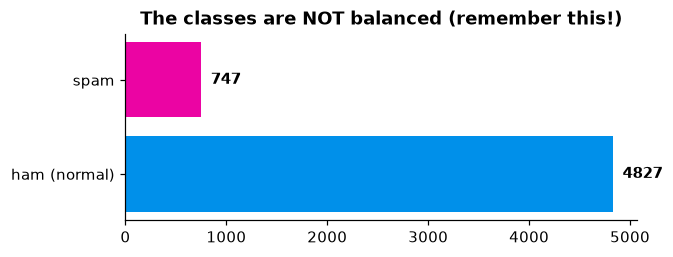

,text,label
3690,You still coming tonight?,ham
3527,"""HEY BABE! FAR 2 SPUN-OUT 2 SPK AT DA MO... DE...",ham
724,Ya even those cookies have jelly on them,ham
3370,Sorry i've not gone to that place. I.ll do so ...,ham
468,When are you going to ride your bike?,ham


In [7]:
FALLBACK_SMS = [  # used only if the download fails (no internet)
    ("Hey, are we still meeting at 6?", "ham"), ("Call me when you get home", "ham"),
    ("Can you buy bread on your way back?", "ham"), ("Happy birthday! Have a great day", "ham"),
    ("I'm running 10 min late, sorry", "ham"), ("Did you finish the homework?", "ham"),
    ("Ok see you tomorrow at the cafe", "ham"), ("Thanks for yesterday, it was fun", "ham"),
    ("The meeting is moved to Monday", "ham"), ("Don't forget mom's dinner tonight", "ham"),
    ("WINNER!! You have won a 1000 cash prize. Call 09061701461 now", "spam"),
    ("FREE entry in 2 a weekly competition to win FA Cup tickets. Text FA to 87121", "spam"),
    ("URGENT! Your mobile number has won a 2000 bonus. Claim now", "spam"),
    ("You have been selected for a free holiday. Reply YES", "spam"),
]

try:
    from datasets import load_dataset
    sms = load_dataset("ucirvine/sms_spam", split="train").to_pandas()
    text_col = "sms" if "sms" in sms.columns else sms.select_dtypes("object").columns[0]
    label_col = "label" if "label" in sms.columns else [c for c in sms.columns if c != text_col][0]
    sms = pd.DataFrame({"text": sms[text_col].str.strip(),
                        "label": sms[label_col].map({0: "ham", 1: "spam"}).fillna(sms[label_col])})
    print("Real dataset downloaded.")
except Exception as e:
    print("Download failed, using a tiny built-in sample instead:", type(e).__name__)
    sms = pd.DataFrame(FALLBACK_SMS * 20, columns=["text", "label"])

counts = sms["label"].value_counts()
print(counts.to_string(), f"\nSpam = {counts.get('spam', 0) / len(sms):.1%} of all messages")

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["ham (normal)", "spam"], [counts.get("ham", 0), counts.get("spam", 0)], color=[BLUE, PINK])
for i, v in enumerate([counts.get("ham", 0), counts.get("spam", 0)]):
    ax.text(v, i, f"  {v}", va="center", fontweight="bold")
ax.set_title("The classes are NOT balanced (remember this!)", fontweight="bold")
plt.show()
display(sms.sample(5, random_state=SEED))

## Step 9: Train two spam filters (in about one second)

1. **The lazy model**: it never reads anything. It always answers the most common class: *ham*.
2. **TF-IDF + Logistic Regression**: the classic method.
   - **TF-IDF** gives each word a weight: frequent in this message but rare elsewhere = important (*"WINNER"*, *"claim"*, *"prize"*).
   - **Logistic regression** learns which words push towards *spam* and which towards *ham*.

We keep **20% of the messages hidden** during training: the **test set**. The model is judged only on messages it has never seen.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    sms["text"], sms["label"], test_size=0.2, stratify=sms["label"], random_state=SEED)

lazy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
spam_filter = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True),
                            LogisticRegression(max_iter=1000, C=10))
t0 = time.perf_counter()
spam_filter.fit(X_train, y_train)
print(f"Trained on {len(X_train)} messages in {time.perf_counter() - t0:.2f} s. Test set: {len(X_test)} messages.")

p_spam = spam_filter.predict_proba(X_test)[:, list(spam_filter.classes_).index("spam")]
pred_filter = np.where(p_spam > THRESHOLD, "spam", "ham")
pred_lazy = lazy.predict(X_test)

Trained on 4459 messages in 4.02 s. Test set: 1115 messages.


## Step 10: The confusion matrix — where exactly does each model go wrong?

Rows = the **truth**, columns = what the model **predicted**.
Look at the top-left box: **spams correctly caught (TP)**.

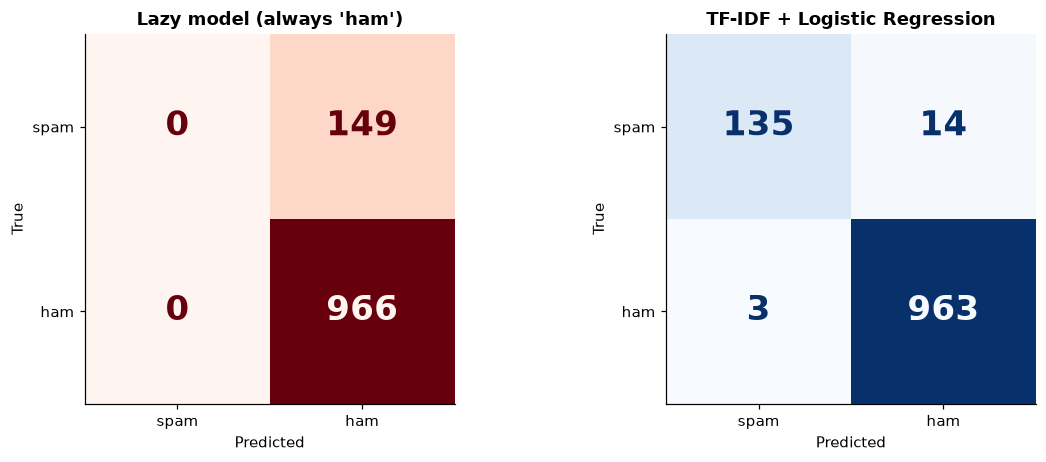

,Lazy model,TF-IDF + LogReg
Accuracy,86.6%,98.5%
Precision (spam),0.0%,97.8%
Recall (spam),0.0%,90.6%
F1 (spam),0.0%,94.1%
Macro-F1,46.4%,96.6%



The lazy model gets 86.6% accuracy... and catches 0 spam.
Accuracy alone would tell us this model is great. The recall and the macro-F1 tell the truth.


In [9]:
LABELS = ["spam", "ham"]

def scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (spam)": precision_score(y_true, y_pred, pos_label="spam", zero_division=0),
        "Recall (spam)": recall_score(y_true, y_pred, pos_label="spam", zero_division=0),
        "F1 (spam)": f1_score(y_true, y_pred, pos_label="spam", zero_division=0),
        "Macro-F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (name, pred, cmap) in zip(axes, [("Lazy model (always 'ham')", pred_lazy, "Reds"),
                                         ("TF-IDF + Logistic Regression", pred_filter, "Blues")]):
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    disp = ConfusionMatrixDisplay(cm, display_labels=LABELS)
    disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format="d")
    for t in disp.text_.ravel():
        t.set_fontsize(22); t.set_fontweight("bold")
    ax.set_title(name, fontweight="bold"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

table = pd.DataFrame({"Lazy model": scores(y_test, pred_lazy), "TF-IDF + LogReg": scores(y_test, pred_filter)})
display(table.style.format("{:.1%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None))

acc_lazy = table.loc["Accuracy", "Lazy model"]
print(f"\nThe lazy model gets {acc_lazy:.1%} accuracy... and catches {int((pred_lazy == 'spam').sum())} spam.")
print("Accuracy alone would tell us this model is great. The recall and the macro-F1 tell the truth.")

### The formulas behind the table

With **TP** = spams caught, **FN** = spams missed, **FP** = normal messages wrongly sent to spam, **TN** = normal messages left alone:

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall}=\frac{TP}{TP+FN}$$

$$F_1=\frac{2\cdot \text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}\qquad \text{Macro-}F_1=\frac{F_1(\text{spam})+F_1(\text{ham})}{2}$$

| Metric | The question it answers | Punishes |
|---|---|---|
| **Precision** | "When it says spam, is it right?" | false alarms (your friend's SMS in the spam folder) |
| **Recall** | "Does it find all the spams?" | missed spams |
| **F1** | "Both at the same time?" | whichever is weaker |
| **Macro-F1** | "Is it good on **every** class, even the small one?" | ignoring the rare class |

## Step 11: The threshold game — you are the boss

The filter gives a **probability** of spam. *You* choose from which probability a message goes to the spam folder.

- **Low threshold** (paranoid): catches almost all spams, but also blocks normal messages.
- **High threshold** (relaxed): never blocks your friends, but lets spams through.

There is **no free lunch**: precision and recall pull in opposite directions.

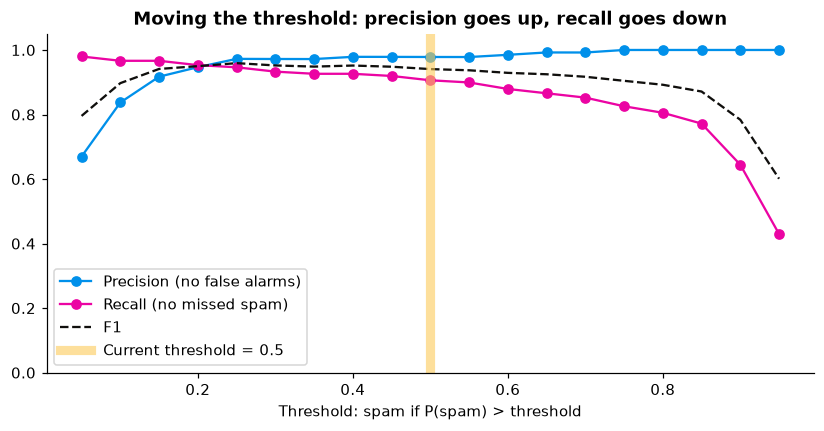

Strategy,Threshold,Spams missed (FN),Friends blocked (FP),Precision,Recall
Paranoid,0.1,5,28,83.7%,96.6%
Balanced,0.5,14,3,97.8%,90.6%
Relaxed,0.9,53,0,100.0%,64.4%


Question for the class: for a SPAM filter, which error is worse? And for a CANCER test?


In [10]:
ths = np.linspace(0.05, 0.95, 19)
P = [precision_score(y_test, np.where(p_spam > t, "spam", "ham"), pos_label="spam", zero_division=0) for t in ths]
R = [recall_score(y_test, np.where(p_spam > t, "spam", "ham"), pos_label="spam", zero_division=0) for t in ths]
F = [f1_score(y_test, np.where(p_spam > t, "spam", "ham"), pos_label="spam", zero_division=0) for t in ths]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ths, P, "-o", color=BLUE, label="Precision (no false alarms)")
ax.plot(ths, R, "-o", color=PINK, label="Recall (no missed spam)")
ax.plot(ths, F, "--", color="#100f0d", label="F1")
ax.axvline(THRESHOLD, color=YELLOW, lw=6, alpha=.6, label=f"Current threshold = {THRESHOLD}")
ax.set_xlabel("Threshold: spam if P(spam) > threshold"); ax.set_ylim(0, 1.05); ax.legend(loc="lower left")
ax.set_title("Moving the threshold: precision goes up, recall goes down", fontweight="bold")
plt.show()

rows = []
for name, t in [("Paranoid", 0.1), ("Balanced", 0.5), ("Relaxed", 0.9)]:
    pred = np.where(p_spam > t, "spam", "ham")
    rows.append({"Strategy": name, "Threshold": t,
                 "Spams missed (FN)": int(((y_test == "spam") & (pred == "ham")).sum()),
                 "Friends blocked (FP)": int(((y_test == "ham") & (pred == "spam")).sum()),
                 "Precision": precision_score(y_test, pred, pos_label="spam", zero_division=0),
                 "Recall": recall_score(y_test, pred, pos_label="spam", zero_division=0)})
display(pd.DataFrame(rows).style.format({"Threshold": "{:.1f}", "Precision": "{:.1%}", "Recall": "{:.1%}"}).hide(axis="index"))
print("Question for the class: for a SPAM filter, which error is worse? And for a CANCER test?")

## Step 12: Look at the mistakes (the habit of good engineers)

A score is a summary. **Reading the errors** tells you *why* the model fails.

In [11]:
errors = pd.DataFrame({"text": X_test.values, "truth": y_test.values, "predicted": pred_filter, "P(spam)": p_spam})
fp = errors[(errors.truth == "ham") & (errors.predicted == "spam")].sort_values("P(spam)", ascending=False).head(5)
fn = errors[(errors.truth == "spam") & (errors.predicted == "ham")].sort_values("P(spam)").head(5)

def error_table(df, title, color):
    rows = "".join(f"<tr><td style='padding:4px 8px'>{r.text[:120]}</td><td style='padding:4px 8px;text-align:center'><b>{r['P(spam)']:.2f}</b></td></tr>"
                   for _, r in df.iterrows()) or "<tr><td>No error of this type!</td><td></td></tr>"
    return (f"<h4 style='color:{color};font-family:sans-serif'>{title}</h4>"
            f"<table style='border:2px solid {color};border-collapse:collapse;font-family:sans-serif;font-size:13px'>"
            f"<tr style='background:{color};color:white'><th style='padding:4px 8px'>Message</th><th>P(spam)</th></tr>{rows}</table>")

display(HTML(error_table(fp, "False alarms (FP): normal messages sent to spam", BLUE)
             + error_table(fn, "Missed spams (FN): spams that reached the inbox", PINK)))

Message,P(spam)
K..u also dont msg or reply to his msg..,0.70
Ok... Ur typical reply...,0.60
Alright i have a new goal now,0.57
Message,P(spam)
"Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?",0.01
"Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get fur",0.03
Sorry I missed your call let's talk when you have the time. I'm on 07090201529,0.04
ROMCAPspam Everyone around should be responding well to your presence since you are so warm and outgoing. You are bringi,0.06
For sale - arsenal dartboard. Good condition but no doubles or trebles!,0.06


## Step 13: Old school vs Transformer on a real benchmark

**SST-2** is a famous test: 872 movie review sentences labeled positive/negative by humans.

- **Model A — TF-IDF + Logistic Regression**: trained here on the 67,000 SST-2 training sentences. Small and fast.
- **Model B — DistilBERT**: the Transformer from Part 1.

We measure three things, like for the vision models: **speed**, **size**, **score**.

Generating test split: 100%|██████████| 1821/1821 [00:00<00:00, 503217.00 examples/s]


SST-2 loaded: 67349 training sentences, 872 test sentences.


,TF-IDF + LogReg,DistilBERT
Accuracy,0.822,0.911
Macro-F1,0.822,0.910
ms per sentence,0.135,24.467
Million parameters,0.081,66.955


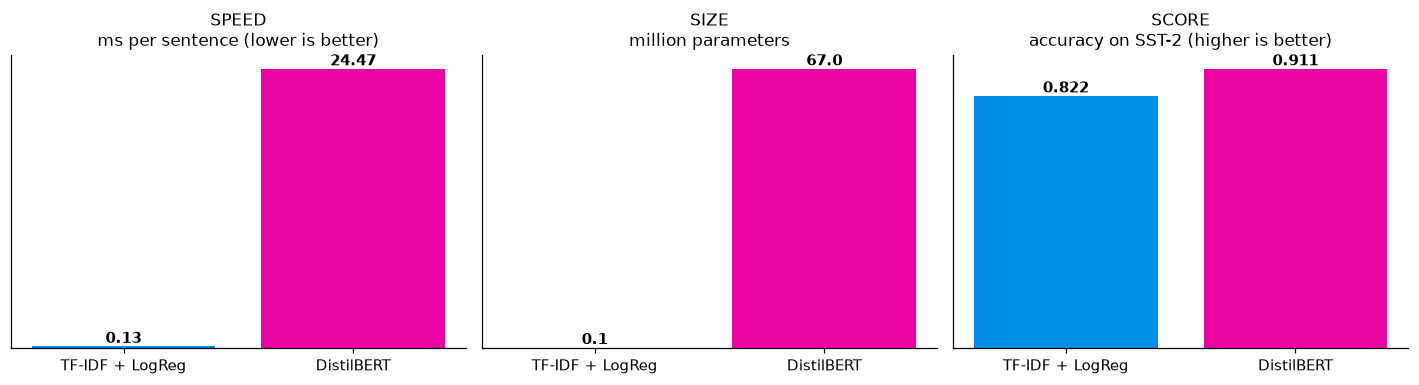

The lesson: the Transformer is more accurate but much heavier and slower. The right model depends on the job.


In [12]:
try:
    from datasets import load_dataset
    sst = load_dataset("stanfordnlp/sst2")
    sst_train = sst["train"].to_pandas()
    sst_test = sst["validation"].to_pandas()
    if BENCHMARK_SIZE:
        sst_test = sst_test.sample(BENCHMARK_SIZE, random_state=SEED)
    HAVE_SST = True
    print(f"SST-2 loaded: {len(sst_train)} training sentences, {len(sst_test)} test sentences.")
except Exception as e:
    HAVE_SST = False
    print("SST-2 could not be downloaded (internet needed). Skipping this step:", type(e).__name__)

if HAVE_SST:
    y_true = sst_test["label"].values                  # 1 = positive, 0 = negative

    tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), LogisticRegression(max_iter=1000, C=4))
    tfidf.fit(sst_train["sentence"], sst_train["label"])
    t0 = time.perf_counter(); pred_a = tfidf.predict(sst_test["sentence"]); ms_a = (time.perf_counter() - t0) * 1000 / len(sst_test)

    t0 = time.perf_counter(); pred_b = (p_positive(sst_test["sentence"]) >= 0.5).astype(int); ms_b = (time.perf_counter() - t0) * 1000 / len(sst_test)

    size_a = len(tfidf[0].vocabulary_) + tfidf[-1].coef_.size     # TF-IDF vocabulary + weights
    bench = pd.DataFrame({
        "TF-IDF + LogReg": {"Accuracy": accuracy_score(y_true, pred_a), "Macro-F1": f1_score(y_true, pred_a, average="macro"),
                            "ms per sentence": ms_a, "Million parameters": tfidf[-1].coef_.size / 1e6},
        "DistilBERT": {"Accuracy": accuracy_score(y_true, pred_b), "Macro-F1": f1_score(y_true, pred_b, average="macro"),
                       "ms per sentence": ms_b, "Million parameters": n_params / 1e6},
    })
    display(bench.style.format("{:.3f}"))

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, (row, title, fmt) in zip(axes, [("ms per sentence", "SPEED\nms per sentence (lower is better)", "%.2f"),
                                             ("Million parameters", "SIZE\nmillion parameters", "%.1f"),
                                             ("Accuracy", "SCORE\naccuracy on SST-2 (higher is better)", "%.3f")]):
        bars = ax.bar(bench.columns, bench.loc[row], color=[BLUE, PINK])
        ax.bar_label(bars, fmt=fmt, fontweight="bold"); ax.set_title(title, fontsize=11); ax.set_yticks([])
    plt.tight_layout(); plt.show()
    print("The lesson: the Transformer is more accurate but much heavier and slower. The right model depends on the job.")

## Step 14: The stress test — scenarios a benchmark does not show

A high benchmark score does not mean the model handles **every kind** of sentence.
We write small groups of sentences on purpose, each testing **one skill** (this idea is called *behavioral testing*, or *CheckList*).

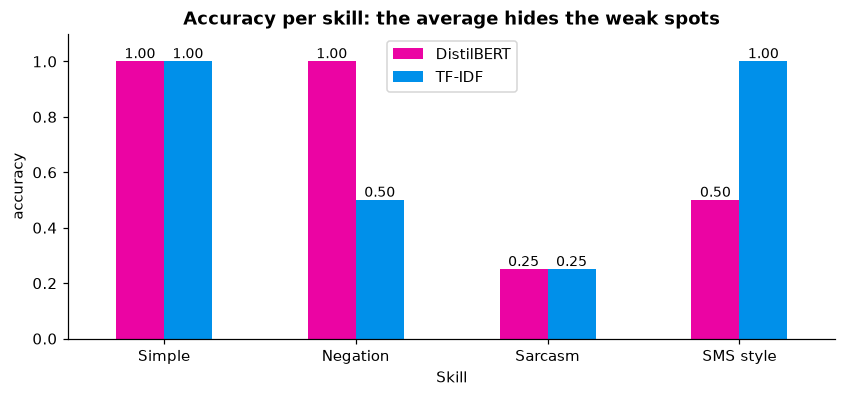

DistilBERT failed on:
   [Sarcasm] Great, another Monday...
   [Sarcasm] Oh wonderful, the bus is late again
   [Sarcasm] Thanks a lot for losing my luggage
   [SMS style] sooo gud omg
   [SMS style] luv it 10/10


In [13]:
STRESS = {
    "Simple":   [("I love this phone", 1), ("This is terrible", 0), ("What a wonderful day", 1), ("I hate waiting in line", 0)],
    "Negation": [("This is not bad at all", 1), ("I don't hate it", 1), ("It is not good", 0), ("I would not recommend it", 0)],
    "Sarcasm":  [("Great, another Monday...", 0), ("Oh wonderful, the bus is late again", 0),
                 ("Thanks a lot for losing my luggage", 0), ("Perfect, my laptop just crashed", 0)],
    "SMS style":[("sooo gud omg", 1), ("worst app evr smh", 0), ("luv it 10/10", 1), ("meh not worth it", 0)],
}

rows, fails = [], []
for skill, items in STRESS.items():
    texts, gold = zip(*items)
    pred = (p_positive(texts) >= 0.5).astype(int)
    rows.append({"Skill": skill, "DistilBERT": accuracy_score(gold, pred),
                 "TF-IDF": accuracy_score(gold, tfidf.predict(list(texts))) if HAVE_SST else np.nan})
    fails += [(skill, t) for t, g, p in zip(texts, gold, pred) if g != p]

stress = pd.DataFrame(rows).set_index("Skill")
ax = stress.plot.bar(figsize=(9, 3.6), color=[PINK, BLUE], rot=0, ylim=(0, 1.1))
ax.set_title("Accuracy per skill: the average hides the weak spots", fontweight="bold"); ax.set_ylabel("accuracy")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=9)
plt.show()
print("DistilBERT failed on:")
for skill, t in fails:
    print(f"   [{skill}] {t}")

## Step 15: Three numbers to remember

| | Question | Metric | Trap |
|---|---|---|---|
| **Accuracy** | How many answers are right? | (TP+TN) / all | Useless when classes are unbalanced (the lazy model!) |
| **Precision / Recall** | False alarms or missed cases? | TP/(TP+FP), TP/(TP+FN) | You can raise one by lowering the other (threshold game) |
| **Macro-F1** | Good on **every** class? | mean of the F1 of each class | Hides which error costs more |

**Which metric should I choose?**

| If... | Look first at |
|---|---|
| Classes are balanced (movie reviews) | Accuracy + F1 |
| One class is rare (spam, fraud, disease) | Recall, Precision, Macro-F1, confusion matrix |
| A missed case is dangerous (medicine, security) | Recall (and choose a low threshold) |
| A false alarm is expensive (blocking a client) | Precision (and choose a high threshold) |

### Things to try
- Change `THRESHOLD` to `0.2` then `0.8` and rerun Steps 9 to 12.
- Add your own sentences to the `STRESS` dictionary (irony, emojis, very long sentences).
- Write a French sentence in the live demo: what happens? (the model only learned English!)

### Common problems
| Problem | Solution |
|---|---|
| Download is slow or fails | Check internet. The models are downloaded only once, then cached |
| `input()` box does not appear | In VS Code it appears at the **top** of the window. Or set `LIVE_DEMO = False` |
| Step 13 is slow | Set `BENCHMARK_SIZE = 200` |
| Different numbers than a friend | Use the same `SEED` |